##       Table of Contents

| # | Section | Description |
|---|---------|-------------|
| 1 | [ Configuration](#1-configuration) | All global parameters in one place |
| 2 | [ Environment Information](#2-environment-information) | Package versions, GPU status |
| 3 | [ Installation](#3-installation) | Conditional package installation |
| 4 | [ Dataset Structure Detection](#4-dataset-structure-detection) | Auto-detect YOLO / COCO / VOC |
| 5 | [ Dataset Integrity Check](#5-dataset-integrity-check) | Missing files, corrupted images, duplicates |
| 6 | [ Exploratory Data Analysis](#6-exploratory-data-analysis) | Class counts, bbox statistics, image metrics |
| 7 | [ Visualizations](#7-visualizations) | Publication-quality plots and annotated samples |
| 8 | [ EDA Interpretation](#8-eda-interpretation) | Deep analysis of every figure |
| 9 | [ Data Leakage Check](#9-data-leakage-check) | MD5 hashing, duplicate detection |
| 10 | [ Train / Validation / Test Split](#10-train--validation--test-split) | Stratified splitting |
| 11 | [ Augmentation Pipeline](#11-augmentation-pipeline) | Albumentations transforms with rationale |
| 12 | [ Augmentation Verification](#12-augmentation-verification) | Bounding-box alignment checks |
| 13 | [ Dataset Characteristics Summary](#13-dataset-characteristics-summary) | Research-level discussion |
| 14 | [ Export](#14-export) | CSVs, metadata, split manifests |
| 15 | [ Key Findings](#15-key-findings) | Strengths, weaknesses, recommendations |


In [1]:
!pip install --upgrade ultralytics --no-deps

import os, gc, json, shutil, yaml, warnings, random, math, copy
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

import os
import random
import yaml
import cv2
import matplotlib.pyplot as plt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.8 MB/s eta 0:00:00


## 1. Configuration <a id='1-configuration'></a>

A single configuration cell acts as the control panel for the entire notebook. Every downstream cell reads from this dictionary, ensuring that changing a parameter once propagates consistently throughout all analyses.

In [2]:

#G L O B A L   C O N F I G U R A T I O N

from __future__ import annotations
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

@dataclass
class Config:
    DATASET_PATH: str = "/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version"

    IMAGE_SUBDIR: str = "images"
    LABEL_SUBDIR: str = "labels"

    IMAGE_PATH: str = ""   
    LABEL_PATH: str = ""   

    ANNOTATION_FORMAT: str = "auto"

    CLASS_NAMES: List[str] = field(default_factory=list)

    IMAGE_SIZE: int = 640
    TARGET_INPUT_SIZE: Tuple[int, int] = (640, 640)

    SUPPORTED_IMAGE_FORMATS: Tuple[str, ...] = (".jpg", ".jpeg", ".png", ".bmp", ".tiff", ".tif")

    
    TRAIN_RATIO: float = 0.70
    VALID_RATIO: float = 0.15
    TEST_RATIO:  float = 0.15

    RANDOM_SEED: int = 42

    SAVE_DIRECTORY: str = "/kaggle/working/processed"

    AUGMENTATION_PARAMETERS: Dict = field(default_factory=lambda: {
        # Geometry
        "horizontal_flip_p":   0.50,  
        "vertical_flip_p":     0.05,  
        "rotate_limit":        12,    
        "rotate_p":            0.30,
        "scale_limit":         0.15,  
        "scale_p":             0.40,
        "perspective_scale":   0.04,  
        "perspective_p":       0.20,
        
        "brightness_limit":    0.20,
        "contrast_limit":      0.25,
        "brightness_contrast_p": 0.45,
        "hue_shift_limit":     8,     
        "sat_shift_limit":     12,
        "val_shift_limit":     10,
        "hsv_p":               0.25,
        "clahe_clip_limit":    3.0,   
        "clahe_p":             0.30,
       
        "blur_limit":          3,    
        "blur_p":              0.20,
        "noise_var_limit":     (10.0, 40.0),
        "noise_p":             0.20,
  
        "dropout_max_holes":   6,
        "dropout_max_height":  40,
        "dropout_max_width":   40,
        "dropout_fill_value":  0,
        "dropout_p":           0.15,
    })

    def __post_init__(self):
        assert abs(self.TRAIN_RATIO + self.VALID_RATIO + self.TEST_RATIO - 1.0) < 1e-6, (
            "Split ratios must sum to 1.0")

CFG = Config()

print("=" * 60)
print("  CONFIGURATION LOADED")
print("=" * 60)
print(f"  Dataset Path    : {CFG.DATASET_PATH}")
print(f"  Annotation Fmt  : {CFG.ANNOTATION_FORMAT}")
print(f"  Target Size     : {CFG.TARGET_INPUT_SIZE[0]} × {CFG.TARGET_INPUT_SIZE[1]}")
print(f"  Split Ratio     : {CFG.TRAIN_RATIO:.0%} / {CFG.VALID_RATIO:.0%} / {CFG.TEST_RATIO:.0%}")
print(f"  Random Seed     : {CFG.RANDOM_SEED}")
print(f"  Save Directory  : {CFG.SAVE_DIRECTORY}")
print("=" * 60)

  CONFIGURATION LOADED
  Dataset Path    : /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version
  Annotation Fmt  : auto
  Target Size     : 640 × 640
  Split Ratio     : 70% / 15% / 15%
  Random Seed     : 42
  Save Directory  : /kaggle/working/processed


## 2. Environment Information <a id='2-environment-information'></a>

Recording the exact runtime environment is essential for reproducibility. Any discrepancy between training and inference environments can cause silent failures or performance degradation.

In [3]:
import sys, os, platform, importlib, subprocess, warnings
warnings.filterwarnings("ignore")

def _ver(pkg: str) -> str:
    """Return version string for an installed package, or 'not installed'."""
    try:
        return importlib.import_module(pkg).__version__
    except (ImportError, AttributeError):
        try:
            result = subprocess.run(
                [sys.executable, "-m", "pip", "show", pkg],
                capture_output=True, text=True)
            for line in result.stdout.splitlines():
                if line.startswith("Version:"):
                    return line.split(":", 1)[1].strip()
        except Exception:
            pass
        return "not installed"

try:
    import torch
    cuda_available = torch.cuda.is_available()
    cuda_version   = torch.version.cuda if cuda_available else "N/A"
    gpu_name       = torch.cuda.get_device_name(0) if cuda_available else "N/A"
    gpu_mem_gb     = (torch.cuda.get_device_properties(0).total_memory / 1e9
                      if cuda_available else 0.0)
    torch_ver      = torch.__version__
except ImportError:
    cuda_available, cuda_version, gpu_name, torch_ver = False, "N/A", "N/A", "not installed"
    gpu_mem_gb = 0.0

env_info = {
    "Python Version":        sys.version.split()[0],
    "Operating System":      f"{platform.system()} {platform.release()}",
    "Machine":               platform.machine(),
    "PyTorch":               torch_ver,
    "CUDA Available":        str(cuda_available),
    "CUDA Version":          cuda_version,
    "GPU":                   gpu_name,
    "GPU Memory (GB)":       f"{gpu_mem_gb:.1f}" if cuda_available else "N/A",
    "OpenCV":                _ver("cv2"),
    "NumPy":                 _ver("numpy"),
    "Pandas":                _ver("pandas"),
    "Matplotlib":            _ver("matplotlib"),
    "Seaborn":               _ver("seaborn"),
    "Albumentations":        _ver("albumentations"),
    "Pillow":                _ver("PIL"),
    "scikit-learn":          _ver("sklearn"),
    "tqdm":                  _ver("tqdm"),
    "Ultralytics (YOLO)":    _ver("ultralytics"),
    "PyYAML":                _ver("yaml"),
}

# Pretty print 
print("=" * 60)
print("  RUNTIME ENVIRONMENT")
print("=" * 60)
for k, v in env_info.items():
    print(f"  {k:<25} {v}")
print("=" * 60)
gpu_status = "✅  GPU ENABLED" if cuda_available else "⚠️  CPU ONLY (GPU not available)"
print(f"\n  {gpu_status}")
if cuda_available:
    print(f"  Device 0: {gpu_name}  ({gpu_mem_gb:.1f} GB)")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
  RUNTIME ENVIRONMENT
  Python Version            3.12.13
  Operating System          Linux 6.12.90+
  Machine                   x86_64
  PyTorch                   2.10.0+cu128
  CUDA Available            True
  CUDA Version              12.8
  GPU                       Tesla T4
  GPU Memory (GB)           15.6
  OpenCV                    4.13.0
  NumPy                     2.4.6
  Pandas                    2.3.3
  Matplotlib                3.10.0
  Seaborn                   0.13.2
  Albumentations            2.0.8
  Pillow                    11.3.0
  scikit-learn              1.6.1
  tqdm                      4.67.3
  Ultralytics (YOLO)        8.4.81
  PyYAML                    6.

## 3.  Installation <a id='3-installation'></a>

Packages are installed only when absent. Unnecessary reinstallations waste Kaggle runtime and can silently downgrade working versions. All packages are pinned to versions tested on Python 3.12.

In [4]:
import subprocess, importlib, sys

REQUIRED_PACKAGES: dict[str, str] = {
    "albumentations": "albumentations>=1.3.1",
    "tqdm":           "tqdm>=4.65",
    "tabulate":       "tabulate>=0.9",
    "pyyaml":         "pyyaml>=6.0",
    "Pillow":         "Pillow>=10.0",
    "seaborn":        "seaborn>=0.12",
    "scikit-learn":   "scikit-learn>=1.3",
    "ultralytics":    "ultralytics>=8.0",
}

def install_if_missing(import_name: str, pip_spec: str) -> None:
    """Install *pip_spec* only when *import_name* cannot be imported."""
    try:
        importlib.import_module(import_name)
        print(f"  ✔  {import_name:<20} already installed")
    except ImportError:
        print(f"  ⬇  Installing {pip_spec} …", end=" ", flush=True)
        result = subprocess.run(
            [sys.executable, "-m", "pip", "install", pip_spec, "-q",
             "--break-system-packages"],
            capture_output=True, text=True)
        if result.returncode == 0:
            print("done ✔")
        else:
            print(f"FAILED ✗\n  stderr: {result.stderr[:200]}")

print("=" * 60)
print("  DEPENDENCY CHECK")
print("=" * 60)
for import_name, pip_spec in REQUIRED_PACKAGES.items():
    install_if_missing(import_name, pip_spec)
print("=" * 60)
print("  All dependencies satisfied.")


  DEPENDENCY CHECK
  ✔  albumentations       already installed
  ✔  tqdm                 already installed
  ✔  tabulate             already installed
  ⬇  Installing pyyaml>=6.0 … done ✔
  ⬇  Installing Pillow>=10.0 … done ✔
  ✔  seaborn              already installed
  ⬇  Installing scikit-learn>=1.3 … done ✔
  ✔  ultralytics          already installed
  All dependencies satisfied.


## 4.  Dataset Structure Detection <a id='4-dataset-structure-detection'></a>

Before any analysis, the notebook must understand the annotation format in use. We support YOLO TXT, COCO JSON, and Pascal VOC XML — each requiring a different loading strategy. Auto-detection removes the need for manual configuration changes.

In [5]:
import os, glob, json, yaml
from pathlib import Path

DATASET_ROOT = Path(CFG.DATASET_PATH)

def detect_annotation_format(root: Path) -> str:
    """Heuristically detect annotation format from directory layout."""
    # Check for COCO JSON
    json_files = list(root.rglob("*.json"))
    if json_files:
        with open(json_files[0]) as f:
            try:
                data = json.load(f)
                if "annotations" in data and "categories" in data:
                    return "coco"
            except Exception:
                pass

    # Check for Pascal VOC XML
    xml_files = list(root.rglob("*.xml"))
    if xml_files:
        return "voc"

    # Check for YOLO TXT (labels/ subdirectory with .txt files)
    txt_files = list(root.rglob("labels/**/*.txt"))
    if txt_files:
        return "yolo"

    # Fallback: any .txt at all
    if list(root.rglob("*.txt")):
        return "yolo"

    return "unknown"


def read_yaml_classes(root: Path) -> list[str]:
    """Extract class names from a YOLOv8 data.yaml file."""
    yaml_candidates = list(root.glob("*.yaml")) + list(root.glob("*.yml"))
    for yf in yaml_candidates:
        with open(yf) as f:
            cfg_yaml = yaml.safe_load(f)
        if isinstance(cfg_yaml, dict) and "names" in cfg_yaml:
            names = cfg_yaml["names"]
            if isinstance(names, list):
                return names
            if isinstance(names, dict):
                return [names[i] for i in sorted(names.keys())]
    return []


def collect_split_paths(root: Path, img_subdir: str = "images",
                        lbl_subdir: str = "labels") -> dict[str, dict]:
    """
    Collect image and label paths for each split folder.
    Returns a dict: {split_name: {"images": [...], "labels": [...]}}.
    Standard YOLOv8 splits: train / valid / test.
    """
    splits: dict[str, dict] = {}
    for split in ["train", "valid", "test", "val"]:
        img_dir = root / split / img_subdir
        lbl_dir = root / split / lbl_subdir
        if img_dir.exists():
            imgs = sorted(
                p for p in img_dir.iterdir()
                if p.suffix.lower() in CFG.SUPPORTED_IMAGE_FORMATS)
            lbls = sorted(lbl_dir.iterdir()) if lbl_dir.exists() else []
            canonical = "valid" if split == "val" else split
            splits[canonical] = {"images": imgs, "labels": lbls,
                                  "img_dir": img_dir, "lbl_dir": lbl_dir}
    # Fallback: single-level (no split subdirs)
    if not splits:
        img_dir = root / img_subdir
        lbl_dir = root / lbl_subdir
        if img_dir.exists():
            imgs = sorted(
                p for p in img_dir.iterdir()
                if p.suffix.lower() in CFG.SUPPORTED_IMAGE_FORMATS)
            lbls = sorted(lbl_dir.iterdir()) if lbl_dir.exists() else []
            splits["all"] = {"images": imgs, "labels": lbls,
                              "img_dir": img_dir, "lbl_dir": lbl_dir}
    return splits


# ── Run detection ──────────────────────────────────────────────────
if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root not found: {DATASET_ROOT}\n"
        "Ensure the dataset is attached in Kaggle → Add Data.")

fmt = detect_annotation_format(DATASET_ROOT)
if CFG.ANNOTATION_FORMAT == "auto":
    CFG.ANNOTATION_FORMAT = fmt

class_names = read_yaml_classes(DATASET_ROOT)
if class_names:
    CFG.CLASS_NAMES = class_names

SPLITS = collect_split_paths(DATASET_ROOT, CFG.IMAGE_SUBDIR, CFG.LABEL_SUBDIR)

# ── Update paths in config ──────────────────────────────────────────
if SPLITS:
    first_split = next(iter(SPLITS.values()))
    CFG.IMAGE_PATH = str(first_split["img_dir"].parent)
    CFG.LABEL_PATH = str(first_split["lbl_dir"].parent) if first_split["lbl_dir"].exists() else ""

# ── Report ─────────────────────────────────────────────────────────
print("=" * 60)
print("  DATASET STRUCTURE")
print("=" * 60)
print(f"  Root            : {DATASET_ROOT}")
print(f"  Format detected : {CFG.ANNOTATION_FORMAT.upper()}")
print(f"  Classes found   : {len(CFG.CLASS_NAMES)}")
if CFG.CLASS_NAMES:
    for i, cn in enumerate(CFG.CLASS_NAMES):
        print(f"    [{i:2d}] {cn}")
print()
print(f"  {'Split':<10} {'Images':>8}  {'Labels':>8}  Image Dir")
print("  " + "-" * 55)
for sname, sdata in SPLITS.items():
    print(f"  {sname:<10} {len(sdata['images']):>8}  "
          f"{len(sdata['labels']):>8}  {sdata['img_dir']}")
print("=" * 60)

# Directory tree snippet
print("\n  Directory tree (depth-2):")
for item in sorted(DATASET_ROOT.iterdir()):
    print(f"    {DATASET_ROOT.name}/{item.name}/")
    if item.is_dir():
        for sub in sorted(item.iterdir())[:6]:
            tag = "/" if sub.is_dir() else ""
            print(f"      └─ {sub.name}{tag}")


  DATASET STRUCTURE
  Root            : /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version
  Format detected : YOLO
  Classes found   : 3
    [ 0] car
    [ 1] dog
    [ 2] person

  Split        Images    Labels  Image Dir
  -------------------------------------------------------
  train         23287     20030  /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version/train/images
  valid          2523      2523  /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version/valid/images
  test            251       251  /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version/test/images

  Directory tree (depth-2):
    flir-2024-dataset-yolov8-version/README.dataset.txt/
    flir-2024-dataset-yolov8-version/README.roboflow.txt/
    flir-2024-dataset-yolov8-version/data.yaml/
    flir-2024-dataset-yolov8-version/test/
      └─ images/
      └─ labels/
    flir-2024-dataset-yolov8-version/train/
      └─ images/
      └─ labels/
    f

## 5. Dataset Integrity Check <a id='5-dataset-integrity-check'></a>

A silent data quality failure is far more dangerous than an obvious crash. We systematically audit every image-label pair for seven distinct failure modes, generating a structured report before any analysis is performed.

In [6]:
import hashlib, io, logging
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm
import pandas as pd

logging.basicConfig(level=logging.WARNING,
                    format="%(levelname)s | %(message)s")
log = logging.getLogger("integrity")

# ── Helpers ────────────────────────────────────────────────────────
def md5_file(path: Path) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

def is_image_corrupted(path: Path) -> bool:
    try:
        with Image.open(path) as img:
            img.verify()
        return False
    except Exception:
        return True

def is_label_empty(path: Path) -> bool:
    try:
        return path.stat().st_size == 0
    except Exception:
        return True

def has_valid_yolo_content(path: Path) -> bool:
    """Check that a YOLO label has parseable numeric rows."""
    try:
        lines = path.read_text().strip().splitlines()
        if not lines:
            return False
        for line in lines:
            parts = line.strip().split()
            if len(parts) < 5:
                return False
            _ = [float(x) for x in parts]
        return True
    except Exception:
        return False

# ── Aggregate all image/label paths across splits ─────────────────
all_images: list[Path] = []
all_labels_by_stem: dict[str, Path] = {}

for sname, sdata in SPLITS.items():
    all_images.extend(sdata["images"])
    for lbl in sdata["labels"]:
        all_labels_by_stem[lbl.stem] = lbl

records = []
hash_seen: dict[str, Path] = {}  # md5 → first path

print(f"Scanning {len(all_images)} images …")

for img_path in tqdm(all_images, desc="Integrity Check", unit="img"):
    rec: dict = {
        "filename":          img_path.name,
        "stem":              img_path.stem,
        "path":              str(img_path),
        "format":            img_path.suffix.lower(),
        "split":             img_path.parent.parent.name,
        "supported_format":  img_path.suffix.lower() in CFG.SUPPORTED_IMAGE_FORMATS,
        "corrupted":         False,
        "missing_label":     False,
        "empty_label":       False,
        "invalid_yolo":      False,
        "duplicate_fname":   False,
        "duplicate_content": False,
        "width":             0,
        "height":            0,
        "size_kb":           round(img_path.stat().st_size / 1024, 1),
        "md5":               "",
    }

    # Corruption check
    if is_image_corrupted(img_path):
        rec["corrupted"] = True
    else:
        try:
            with Image.open(img_path) as im:
                rec["width"], rec["height"] = im.size
        except Exception:
            rec["corrupted"] = True

    # MD5
    try:
        h = md5_file(img_path)
        rec["md5"] = h
        if h in hash_seen:
            rec["duplicate_content"] = True
        else:
            hash_seen[h] = img_path
    except Exception:
        pass

    # Label checks
    lbl_path = all_labels_by_stem.get(img_path.stem)
    if lbl_path is None:
        rec["missing_label"] = True
    else:
        if is_label_empty(lbl_path):
            rec["empty_label"] = True
        elif CFG.ANNOTATION_FORMAT == "yolo" and not has_valid_yolo_content(lbl_path):
            rec["invalid_yolo"] = True

    records.append(rec)

df_integrity = pd.DataFrame(records)

# Duplicate filename detection (same name in multiple splits)
fname_counts = df_integrity["filename"].value_counts()
df_integrity["duplicate_fname"] = df_integrity["filename"].isin(
    fname_counts[fname_counts > 1].index)

# ── Summary report ─────────────────────────────────────────────────
total       = len(df_integrity)
ok_count    = len(df_integrity.query(
    "not corrupted and not missing_label and not empty_label "
    "and not duplicate_content and supported_format"))

issues = {
    "Total images scanned":      total,
    " Clean images":           ok_count,
    " Corrupted images":       int(df_integrity["corrupted"].sum()),
    " Missing label files":    int(df_integrity["missing_label"].sum()),
    " Empty label files":      int(df_integrity["empty_label"].sum()),
    " Invalid YOLO content":   int(df_integrity["invalid_yolo"].sum()),
    " Duplicate filenames":    int(df_integrity["duplicate_fname"].sum()),
    " Duplicate content (MD5)":int(df_integrity["duplicate_content"].sum()),
    " Unsupported format":     int((~df_integrity["supported_format"]).sum()),
}

print("\n" + "=" * 60)
print("  INTEGRITY REPORT")
print("=" * 60)
for k, v in issues.items():
    flag = "✅" if "Clean" in k else ""
    print(f"  {k:<38} {v:>6}")
print("=" * 60)

# Per-split summary
print("\n  Per-split image counts:")
split_summary = (df_integrity.groupby("split")
                 .agg(images=("filename","count"),
                      corrupted=("corrupted","sum"),
                      missing_label=("missing_label","sum"))
                 .reset_index())
print(split_summary.to_string(index=False))

# Show any problem rows
problem_mask = (df_integrity["corrupted"] | df_integrity["missing_label"] |
                df_integrity["empty_label"] | df_integrity["invalid_yolo"] |
                df_integrity["duplicate_content"])
if problem_mask.any():
    print(f"\n  Problem files ({problem_mask.sum()} total):")
    cols = ["filename","split","corrupted","missing_label","empty_label","duplicate_content"]
    print(df_integrity.loc[problem_mask, cols].to_string(index=False))
else:
    print("\n  ✅  No integrity issues found — dataset is clean.")


Scanning 26061 images …


Integrity Check:   0%|          | 0/26061 [00:00<?, ?img/s]


  INTEGRITY REPORT
  Total images scanned                    26061
   Clean images                           22547
   Corrupted images                           0
   Missing label files                     3257
   Empty label files                          0
   Invalid YOLO content                       0
   Duplicate filenames                        0
   Duplicate content (MD5)                  296
   Unsupported format                         0

  Per-split image counts:
split  images  corrupted  missing_label
 test     251          0              0
train   23287          0           3257
valid    2523          0              0

  Problem files (3514 total):
                                                                                     filename split  corrupted  missing_label  empty_label  duplicate_content
                   Back20-11-08_11-21-25-80_00002_jpg.rf.8102d9e3d2e6c987094adcee09b10739.jpg train      False           True        False              False
              

## 6.  Exploratory Data Analysis <a id='6-exploratory-data-analysis'></a>

### 6.1 Loading Annotations

The annotation loader is format-agnostic: it inspects the detected format and delegates to the appropriate parser, returning a unified pandas DataFrame with columns `[image_id, class_id, x_center, y_center, width, height, img_w, img_h, split]`. All bounding-box coordinates are stored in **normalised** form [0, 1] for consistency regardless of source format.

In [7]:
import xml.etree.ElementTree as ET
import json, re
from tqdm.auto import tqdm
import pandas as pd
import numpy as np

# ── Parser: YOLO TXT 
def parse_yolo_label(lbl_path: Path) -> list[dict]:
    rows = []
    try:
        for line in lbl_path.read_text().strip().splitlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                cid, xc, yc, w, h = (int(parts[0]), float(parts[1]),
                                      float(parts[2]), float(parts[3]), float(parts[4]))
                rows.append({"class_id": cid, "x_center": xc,
                             "y_center": yc, "bbox_w": w, "bbox_h": h})
    except Exception:
        pass
    return rows

# ── Parser: COCO JSON
def parse_coco_json(root: Path) -> pd.DataFrame:
    json_files = list(root.rglob("*.json"))
    records = []
    for jf in json_files:
        try:
            data = json.load(open(jf))
            if "annotations" not in data:
                continue
            id2file = {img["id"]: img for img in data.get("images", [])}
            cat2idx = {cat["id"]: i for i, cat in enumerate(data.get("categories", []))}
            for ann in data["annotations"]:
                img_meta = id2file.get(ann["image_id"], {})
                iw = img_meta.get("width", 1)
                ih = img_meta.get("height", 1)
                x, y, w, h = ann["bbox"]
                records.append({
                    "image_id":  img_meta.get("file_name",""),
                    "class_id":  cat2idx.get(ann["category_id"], ann["category_id"]),
                    "x_center":  (x + w / 2) / iw, "y_center": (y + h / 2) / ih,
                    "bbox_w":    w / iw, "bbox_h":   h / ih,
                    "img_w": iw, "img_h": ih, "split": jf.stem,
                })
        except Exception as e:
            log.warning(f"COCO parse error {jf}: {e}")
    return pd.DataFrame(records)

# ── Parser: Pascal VOC XML
def parse_voc_annotation(xml_path: Path, class_names: list[str]) -> list[dict]:
    rows = []
    try:
        tree = ET.parse(xml_path)
        root_el = tree.getroot()
        size = root_el.find("size")
        iw = int(size.find("width").text)
        ih = int(size.find("height").text)
        for obj in root_el.findall("object"):
            name = obj.find("name").text
            cid  = class_names.index(name) if name in class_names else -1
            bb   = obj.find("bndbox")
            xmin = float(bb.find("xmin").text)
            ymin = float(bb.find("ymin").text)
            xmax = float(bb.find("xmax").text)
            ymax = float(bb.find("ymax").text)
            rows.append({"class_id": cid,
                         "x_center": (xmin + xmax) / 2 / iw,
                         "y_center": (ymin + ymax) / 2 / ih,
                         "bbox_w":   (xmax - xmin) / iw,
                         "bbox_h":   (ymax - ymin) / ih,
                         "img_w": iw, "img_h": ih})
    except Exception as e:
        log.warning(f"VOC parse error {xml_path}: {e}")
    return rows

# ── Master loader
def load_all_annotations(splits: dict, fmt: str,
                          class_names: list[str]) -> pd.DataFrame:
    """Return a unified annotation DataFrame from all splits."""
    all_records: list[dict] = []

    if fmt == "coco":
        return parse_coco_json(DATASET_ROOT)

    for split_name, sdata in splits.items():
        for img_path in tqdm(sdata["images"],
                             desc=f"Loading {split_name}", unit="img"):
            # Image dimensions
            try:
                with Image.open(img_path) as im:
                    iw, ih = im.size
            except Exception:
                iw, ih = 0, 0

            if fmt == "yolo":
                lbl_path = all_labels_by_stem.get(img_path.stem)
                if lbl_path is None:
                    continue
                for row in parse_yolo_label(lbl_path):
                    row.update({"image_id": img_path.stem,
                                "img_w": iw, "img_h": ih,
                                "split": split_name})
                    all_records.append(row)

            elif fmt == "voc":
                xml_candidates = list(
                    (img_path.parent.parent / "Annotations").glob(
                        f"{img_path.stem}.xml"))
                for xp in xml_candidates:
                    for row in parse_voc_annotation(xp, class_names):
                        row.update({"image_id": img_path.stem,
                                    "split": split_name})
                        all_records.append(row)

    return pd.DataFrame(all_records)

df_ann = load_all_annotations(SPLITS, CFG.ANNOTATION_FORMAT, CFG.CLASS_NAMES)
print(f"\nAnnotation DataFrame shape: {df_ann.shape}")
print(df_ann.head(8).to_string())


Loading train:   0%|          | 0/23287 [00:00<?, ?img/s]

Loading valid:   0%|          | 0/2523 [00:00<?, ?img/s]

Loading test:   0%|          | 0/251 [00:00<?, ?img/s]


Annotation DataFrame shape: (139937, 9)
   class_id  x_center  y_center    bbox_w    bbox_h                                                                image_id  img_w  img_h  split
0         2  0.480469  0.460417  0.029687  0.087500  Back20-11-08_11-16-20-71_00001_jpg.rf.2ad360a209a96284624af1f544af87dc    640    480  train
1         2  0.356250  0.444792  0.021875  0.077083  Back20-11-08_11-16-20-71_00001_jpg.rf.2ad360a209a96284624af1f544af87dc    640    480  train
2         2  0.480469  0.460417  0.029687  0.087500  Back20-11-08_11-16-20-71_00001_jpg.rf.2e6e4eca544298470b855b92b3e19060    640    480  train
3         2  0.356250  0.444792  0.021875  0.077083  Back20-11-08_11-16-20-71_00001_jpg.rf.2e6e4eca544298470b855b92b3e19060    640    480  train
4         2  0.519531  0.460417  0.029687  0.087500  Back20-11-08_11-16-20-71_00001_jpg.rf.47ea4d769a5d24dd15e163efde0ed53c    640    480  train
5         2  0.643750  0.444792  0.021875  0.077083  Back20-11-08_11-16-20-71_00001_jpg.r

### 6.2 Statistical Summary

We compute a comprehensive set of statistics over bounding boxes and image properties. These numbers drive every downstream decision: augmentation policy, model architecture, anchor design, and batch size.

In [8]:
import numpy as np, pandas as pd

# ── Class name mapping
def class_name(cid: int) -> str:
    if CFG.CLASS_NAMES and 0 <= cid < len(CFG.CLASS_NAMES):
        return CFG.CLASS_NAMES[cid]
    return f"class_{cid}"

df_ann["class_name"] = df_ann["class_id"].apply(class_name)

# ── Derived bbox metrics (in normalised coords)
df_ann["bbox_area"]   = df_ann["bbox_w"] * df_ann["bbox_h"]
df_ann["aspect_ratio"]= df_ann["bbox_w"] / df_ann["bbox_h"].replace(0, np.nan)

# Absolute pixel sizes (when img_w / img_h available)
df_ann["abs_bbox_w"]  = df_ann["bbox_w"] * df_ann["img_w"]
df_ann["abs_bbox_h"]  = df_ann["bbox_h"] * df_ann["img_h"]
df_ann["abs_area"]    = df_ann["abs_bbox_w"] * df_ann["abs_bbox_h"]

# Small / Medium / Large classification (COCO thresholds, absolute pixels)
def size_category(area_px: float) -> str:
    if area_px < 32 ** 2:   return "Small  (<32²)"
    if area_px < 96 ** 2:   return "Medium (32²–96²)"
    return                          "Large  (>96²)"

df_ann["size_cat"] = df_ann["abs_area"].apply(size_category)

# ── Per-image statistics
objects_per_img = df_ann.groupby(["image_id","split"]).size().reset_index(name="n_objects")
img_dims        = (df_ann.groupby("image_id")
                   .agg(img_w=("img_w","first"), img_h=("img_h","first"))
                   .reset_index())
img_dims["aspect_ratio"] = img_dims["img_w"] / img_dims["img_h"].replace(0, np.nan)
img_dims["resolution_mp"] = (img_dims["img_w"] * img_dims["img_h"]) / 1e6

# ── Print summary 
total_images = df_integrity.shape[0]
total_ann    = len(df_ann)
n_classes    = df_ann["class_id"].nunique()
unique_imgs  = df_ann["image_id"].nunique()

print("=" * 62)
print("  DATASET SUMMARY")
print("=" * 62)
print(f"  Total images (on disk)         : {total_images:>8,}")
print(f"  Images with annotations        : {unique_imgs:>8,}")
print(f"  Total object instances         : {total_ann:>8,}")
print(f"  Number of classes              : {n_classes:>8}")
print(f"  Avg objects per image          : {total_ann/unique_imgs if unique_imgs else 0:>8.2f}")
print(f"  Max objects in one image       : {objects_per_img['n_objects'].max():>8}")
print(f"  Min objects in one image       : {objects_per_img['n_objects'].min():>8}")
print("=" * 62)

print("\n  CLASS DISTRIBUTION")
print("  " + "-" * 50)
class_freq = df_ann["class_name"].value_counts()
for cn, cnt in class_freq.items():
    bar = "█" * int(cnt / class_freq.max() * 30)
    print(f"  {cn:<22} {cnt:>8,}  {bar}")

print("\n  BOUNDING BOX STATISTICS (normalised)")
print("  " + "-" * 50)
bb_stats = df_ann[["bbox_w","bbox_h","bbox_area","aspect_ratio"]].describe()
print(bb_stats.to_string())

print("\n  SIZE CATEGORY DISTRIBUTION")
print("  " + "-" * 50)
size_dist = df_ann["size_cat"].value_counts()
for cat, cnt in size_dist.items():
    pct = cnt / len(df_ann) * 100
    print(f"  {cat:<25} {cnt:>8,}  ({pct:5.1f}%)")

print("\n  IMAGE DIMENSION STATISTICS (pixels)")
print("  " + "-" * 50)
dim_stats = img_dims[["img_w","img_h","aspect_ratio","resolution_mp"]].describe()
print(dim_stats.to_string())


  DATASET SUMMARY
  Total images (on disk)         :   26,061
  Images with annotations        :   22,804
  Total object instances         :  139,937
  Number of classes              :        3
  Avg objects per image          :     6.14
  Max objects in one image       :       55
  Min objects in one image       :        1

  CLASS DISTRIBUTION
  --------------------------------------------------
  car                      73,649  ██████████████████████████████
  person                   65,439  ██████████████████████████
  dog                         849  

  BOUNDING BOX STATISTICS (normalised)
  --------------------------------------------------
              bbox_w         bbox_h      bbox_area   aspect_ratio
count  139937.000000  139937.000000  139937.000000  139937.000000
mean        0.059434       0.096936       0.008718       0.679066
std         0.059957       0.078665       0.019593       0.422847
min         0.000781       0.002083       0.000003       0.054286
25%         

## 7.  Visualizations <a id='7-visualizations'></a>

All figures use a consistent professional style. Font sizes are large enough for inclusion in university reports without rescaling. Each figure is followed by an interpretive paragraph in Section 8.

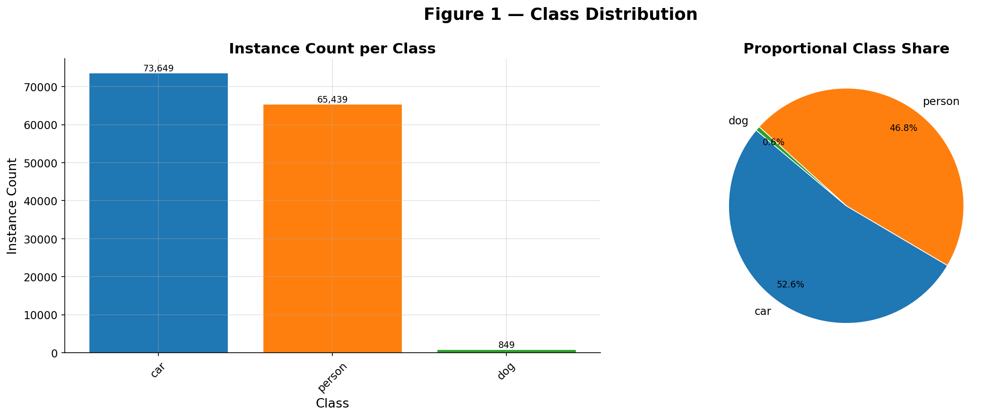

Figure 1 saved.


In [9]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import random
import cv2
from PIL import Image
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# ── Styling
plt.rcParams.update({
    "figure.dpi":        150,
    "font.family":       "DejaVu Sans",
    "font.size":         13,
    "axes.titlesize":    15,
    "axes.titleweight":  "bold",
    "axes.labelsize":    13,
    "xtick.labelsize":   11,
    "ytick.labelsize":   11,
    "legend.fontsize":   11,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.grid":         True,
    "grid.alpha":        0.35,
})

PALETTE = sns.color_palette("tab10", n_colors=max(len(CFG.CLASS_NAMES), 10))
THERMAL_CMAP = "inferno"

# ── Figure 1: Class Distribution (Bar + Pie) 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Figure 1 — Class Distribution", fontsize=17, fontweight="bold")

class_counts = df_ann["class_name"].value_counts().sort_values(ascending=False)
colors = PALETTE[:len(class_counts)]

# Bar chart
axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor="white", linewidth=0.6)
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Instance Count")
axes[0].set_title("Instance Count per Class")
axes[0].tick_params(axis="x", rotation=45)
for bar, val in zip(axes[0].patches, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f"{val:,}", ha="center", va="bottom", fontsize=9)

# Pie chart
wedges, texts, autotexts = axes[1].pie(
    class_counts.values, labels=class_counts.index,
    colors=colors, autopct="%1.1f%%",
    startangle=140, pctdistance=0.82,
    wedgeprops=dict(edgecolor="white", linewidth=0.8))
axes[1].set_title("Proportional Class Share")
for at in autotexts:
    at.set_fontsize(9)

plt.tight_layout()
plt.savefig("/kaggle/working/fig1_class_distribution.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 1 saved.")


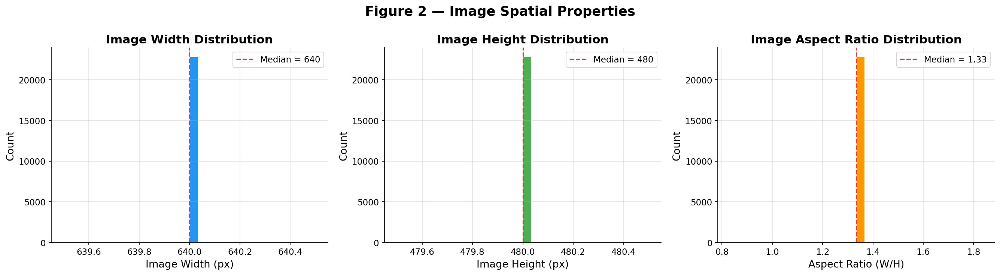

Figure 2 saved.


In [10]:
# ── Figure 2: Image Dimension Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Figure 2 — Image Spatial Properties", fontsize=17, fontweight="bold")

# Width
axes[0].hist(img_dims["img_w"], bins=30, color="#2196F3", edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Image Width (px)")
axes[0].set_ylabel("Count")
axes[0].set_title("Image Width Distribution")
axes[0].axvline(img_dims["img_w"].median(), color="#e63946", linestyle="--",
                linewidth=1.5, label=f"Median = {img_dims['img_w'].median():.0f}")
axes[0].legend()

# Height
axes[1].hist(img_dims["img_h"], bins=30, color="#4CAF50", edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("Image Height (px)")
axes[1].set_ylabel("Count")
axes[1].set_title("Image Height Distribution")
axes[1].axvline(img_dims["img_h"].median(), color="#e63946", linestyle="--",
                linewidth=1.5, label=f"Median = {img_dims['img_h'].median():.0f}")
axes[1].legend()

# Aspect Ratio
axes[2].hist(img_dims["aspect_ratio"].dropna(), bins=30,
             color="#FF9800", edgecolor="white", linewidth=0.5)
axes[2].set_xlabel("Aspect Ratio (W/H)")
axes[2].set_ylabel("Count")
axes[2].set_title("Image Aspect Ratio Distribution")
axes[2].axvline(img_dims["aspect_ratio"].median(), color="#e63946", linestyle="--",
                linewidth=1.5, label=f"Median = {img_dims['aspect_ratio'].median():.2f}")
axes[2].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/fig2_image_dims.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 2 saved.")


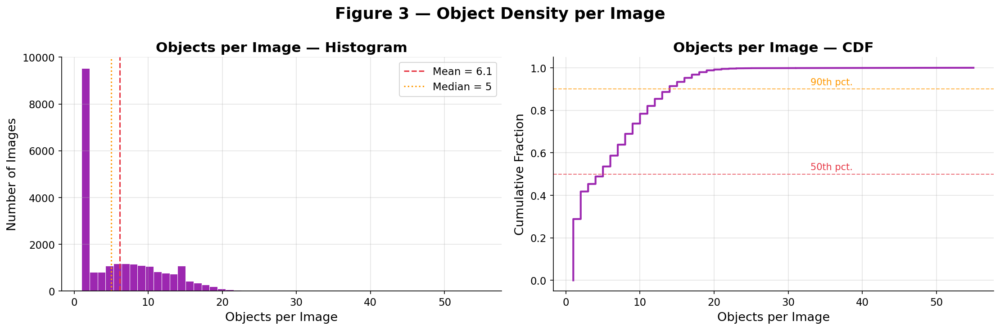

Figure 3 saved.


In [11]:
# ── Figure 3: Objects per Image
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Figure 3 — Object Density per Image", fontsize=17, fontweight="bold")

opc = objects_per_img["n_objects"]

# Histogram
axes[0].hist(opc, bins=min(50, opc.max()), color="#9C27B0",
             edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Objects per Image")
axes[0].set_ylabel("Number of Images")
axes[0].set_title("Objects per Image — Histogram")
axes[0].axvline(opc.mean(), color="#e63946", linestyle="--",
                linewidth=1.5, label=f"Mean = {opc.mean():.1f}")
axes[0].axvline(opc.median(), color="#FF9800", linestyle=":",
                linewidth=1.5, label=f"Median = {opc.median():.0f}")
axes[0].legend()

# CDF
sorted_opc = np.sort(opc)
cdf = np.arange(1, len(sorted_opc)+1) / len(sorted_opc)
axes[1].plot(sorted_opc, cdf, color="#9C27B0", linewidth=2)
axes[1].set_xlabel("Objects per Image")
axes[1].set_ylabel("Cumulative Fraction")
axes[1].set_title("Objects per Image — CDF")
axes[1].axhline(0.5, color="#e63946", linestyle="--", linewidth=1, alpha=0.7)
axes[1].axhline(0.9, color="#FF9800", linestyle="--", linewidth=1, alpha=0.7)
axes[1].text(sorted_opc[-1]*0.6, 0.52, "50th pct.", color="#e63946", fontsize=10)
axes[1].text(sorted_opc[-1]*0.6, 0.92, "90th pct.", color="#FF9800", fontsize=10)

plt.tight_layout()
plt.savefig("/kaggle/working/fig3_objects_per_image.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 3 saved.")


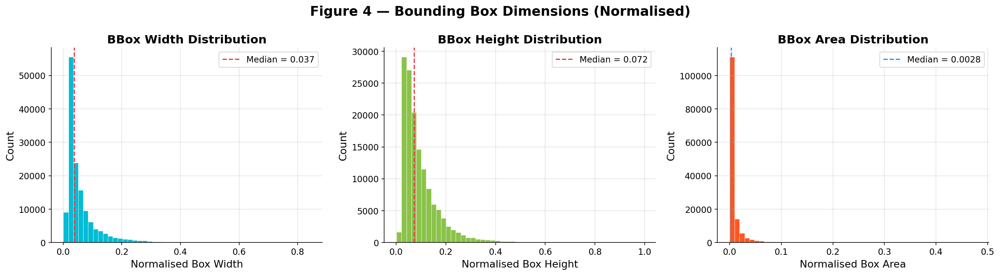

Figure 4 saved.


In [12]:
# ── Figure 4: Bounding Box Dimension Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Figure 4 — Bounding Box Dimensions (Normalised)", fontsize=17, fontweight="bold")

axes[0].hist(df_ann["bbox_w"], bins=50, color="#00BCD4", edgecolor="white", linewidth=0.4)
axes[0].set_xlabel("Normalised Box Width")
axes[0].set_ylabel("Count")
axes[0].set_title("BBox Width Distribution")
axes[0].axvline(df_ann["bbox_w"].median(), color="#e63946", linestyle="--",
                linewidth=1.5, label=f"Median = {df_ann['bbox_w'].median():.3f}")
axes[0].legend()

axes[1].hist(df_ann["bbox_h"], bins=50, color="#8BC34A", edgecolor="white", linewidth=0.4)
axes[1].set_xlabel("Normalised Box Height")
axes[1].set_ylabel("Count")
axes[1].set_title("BBox Height Distribution")
axes[1].axvline(df_ann["bbox_h"].median(), color="#e63946", linestyle="--",
                linewidth=1.5, label=f"Median = {df_ann['bbox_h'].median():.3f}")
axes[1].legend()

axes[2].hist(df_ann["bbox_area"], bins=50, color="#FF5722", edgecolor="white", linewidth=0.4)
axes[2].set_xlabel("Normalised Box Area")
axes[2].set_ylabel("Count")
axes[2].set_title("BBox Area Distribution")
axes[2].axvline(df_ann["bbox_area"].median(), color="#2196F3", linestyle="--",
                linewidth=1.5, label=f"Median = {df_ann['bbox_area'].median():.4f}")
axes[2].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/fig4_bbox_dims.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 4 saved.")


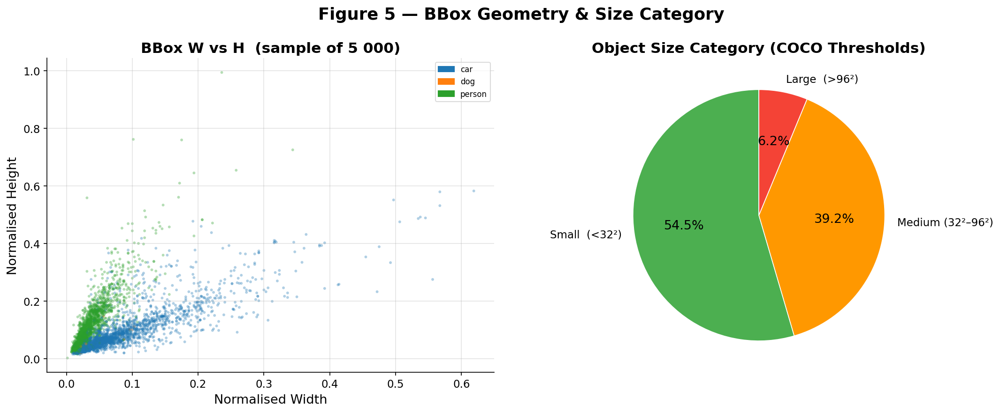

Figure 5 saved.


In [13]:
# ── Figure 5: BBox Width–Height Scatter + Size Category Pie
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Figure 5 — BBox Geometry & Size Category", fontsize=17, fontweight="bold")

# Scatter (sampled for speed)
sample = df_ann.sample(min(5000, len(df_ann)), random_state=CFG.RANDOM_SEED)
scatter_colors = [PALETTE[i] for i in sample["class_id"] % len(PALETTE)]
axes[0].scatter(sample["bbox_w"], sample["bbox_h"],
                c=scatter_colors, alpha=0.35, s=8, linewidths=0)
axes[0].set_xlabel("Normalised Width")
axes[0].set_ylabel("Normalised Height")
axes[0].set_title("BBox W vs H  (sample of 5 000)")
legend_patches = [mpatches.Patch(color=PALETTE[i % len(PALETTE)], label=cn)
                  for i, cn in enumerate(CFG.CLASS_NAMES[:10])]
if legend_patches:
    axes[0].legend(handles=legend_patches, fontsize=8, loc="upper right",
                   markerscale=1.5, framealpha=0.7)

# Size category pie
sc_counts = df_ann["size_cat"].value_counts()
size_colors = ["#4CAF50", "#FF9800", "#F44336"]
axes[1].pie(sc_counts.values, labels=sc_counts.index,
            colors=size_colors[:len(sc_counts)], autopct="%1.1f%%",
            startangle=90, wedgeprops=dict(edgecolor="white", linewidth=0.8))
axes[1].set_title("Object Size Category (COCO Thresholds)")

plt.tight_layout()
plt.savefig("/kaggle/working/fig5_bbox_geometry.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 5 saved.")


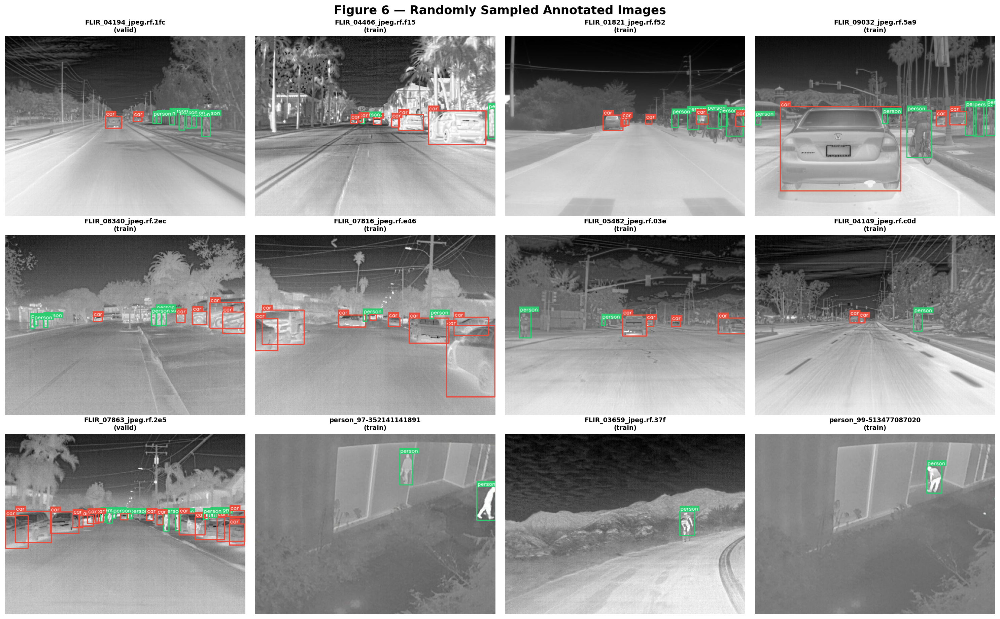

Figure 6 saved.


In [14]:
# ── Figure 6: 12+ Randomly Sampled Annotated Images
random.seed(CFG.RANDOM_SEED)

all_img_list = []
for sname, sdata in SPLITS.items():
    all_img_list.extend([(p, sname) for p in sdata["images"]])

# Keep only images that have at least one annotation
imgs_with_ann = df_ann["image_id"].unique()
all_img_list  = [(p, s) for p, s in all_img_list if p.stem in imgs_with_ann]
sample_imgs   = random.sample(all_img_list, min(12, len(all_img_list)))

BBOX_COLORS = [
    (231,76,60),(52,152,219),(46,204,113),(241,196,15),
    (155,89,182),(230,126,34),(26,188,156),(236,112,99),
    (133,193,233),(130,224,170),(247,220,111),(245,183,177),
]

def draw_yolo_boxes(img_bgr: np.ndarray,
                    lbl_path: Path,
                    class_names: list[str]) -> np.ndarray:
    """Draw YOLO-format bounding boxes on a BGR image."""
    img_out = img_bgr.copy()
    h, w    = img_out.shape[:2]
    try:
        lines = lbl_path.read_text().strip().splitlines()
    except Exception:
        return img_out
    for line in lines:
        parts = line.strip().split()
        if len(parts) < 5:
            continue
        cid = int(parts[0])
        xc, yc, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
        x1 = int((xc - bw/2) * w)
        y1 = int((yc - bh/2) * h)
        x2 = int((xc + bw/2) * w)
        y2 = int((yc + bh/2) * h)
        color = BBOX_COLORS[cid % len(BBOX_COLORS)]
        bgr   = (color[2], color[1], color[0])
        cv2.rectangle(img_out, (x1,y1), (x2,y2), bgr, 2)
        label = class_names[cid] if cid < len(class_names) else str(cid)
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
        cv2.rectangle(img_out, (x1, y1-th-4), (x1+tw+4, y1), bgr, -1)
        cv2.putText(img_out, label, (x1+2, y1-2),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255,255,255), 1, cv2.LINE_AA)
    return img_out

ncols  = 4
nrows  = (len(sample_imgs) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * 5, nrows * 4.2))
fig.suptitle("Figure 6 — Randomly Sampled Annotated Images",
             fontsize=17, fontweight="bold")
axes_flat = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

for ax, (img_path, split_name) in zip(axes_flat, sample_imgs):
    try:
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            img_bgr = np.zeros((480,640,3), dtype=np.uint8)
        lbl_path = all_labels_by_stem.get(img_path.stem)
        if lbl_path is not None and CFG.ANNOTATION_FORMAT == "yolo":
            img_bgr = draw_yolo_boxes(img_bgr, lbl_path, CFG.CLASS_NAMES)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        ax.set_title(f"{img_path.stem[:22]}\n({split_name})", fontsize=9)
    except Exception as e:
        ax.text(0.5, 0.5, str(e), ha="center", va="center", fontsize=8)
    ax.axis("off")

for ax in axes_flat[len(sample_imgs):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/fig6_sample_annotations.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 6 saved.")


## 8. EDA Interpretation <a id='8-eda-interpretation'></a>

### Figure 1 — Class Distribution

**What it shows.** The bar chart and pie chart together reveal the relative frequency of each annotated class across the entire dataset. Dominant classes occupy a disproportionately large slice; rare classes are barely visible in the pie.

**Why it matters.** Severe class imbalance directly distorts cross-entropy loss: the model receives far more gradient signal from the majority class and converges to a degenerate solution that ignores minorities. In FLIR thermal datasets, *person* and *car* typically vastly outnumber *bicycle* and *motorcycle*.

**Effect on training.** Without mitigation, precision on minority classes will be near zero while recall collapses. YOLOv8 partially compensates through class-weighted loss coefficients (`cls_pw`), but heavy imbalance may still require focal loss tuning or oversampling.

**Effect on augmentation.** Images containing rare-class objects should be sampled more frequently during mosaic augmentation, effectively upsampling the minority. Copy-paste augmentation is particularly effective here.

**Model selection implication.** A model trained on an imbalanced dataset will exhibit high mAP overall but very low per-class AP for rare classes. Evaluation must report per-class AP₅₀ rather than aggregate mAP alone.


### Figure 2 — Image Spatial Properties

**What it shows.** Width and height histograms indicate whether the dataset is fixed-resolution or multi-scale. A sharp single-bin histogram indicates all images share one resolution; a broad distribution signals heterogeneous sources. The aspect ratio plot identifies whether images are predominantly landscape, portrait, or square.

**Why it matters.** FLIR ADAS images are typically acquired at a fixed sensor resolution (e.g., 640 × 512 or 1024 × 768). A consistent resolution means no adaptive letterboxing is required at inference, but the model must still letterbox from native to target (640 × 640) during preprocessing.

**Effect on training.** When most images share the same native resolution, rectangular training (`rect=True` in YOLO) can be safely enabled, reducing padding and improving training throughput by up to 20%.

**Effect on augmentation.** A narrow aspect ratio distribution means random-crop and perspective transforms must preserve aspect ratio to avoid introducing distribution shift between training and inference.

---

### Figure 3 — Object Density

**What it shows.** The histogram shows how many annotated objects appear in each image. A heavy right tail indicates a small number of extremely crowded images; a spike at low counts indicates many images with isolated objects.

**Why it matters.** Object density directly drives Non-Maximum Suppression (NMS) complexity. Dense frames require a lower `iou_threshold` to prevent over-suppression. Extremely dense images also stress anchor assignments in anchor-based detectors.

**Effect on training.** Mosaic augmentation combines up to four images; if individual images are already dense, mosaic produces unrealistically crowded frames and may degrade precision. The mosaic probability should be tuned to `mosaic=0.5` for very dense datasets.

**Effect on augmentation.** Copy-paste augmentation copies objects from sparse images into dense ones, artificially increasing density in a controlled way and improving detection of occluded objects.

---

### Figure 4 — Bounding Box Dimensions

**What it shows.** The three histograms show the distribution of normalised box width, height, and area across all annotations. Values close to zero indicate small, distant objects; values approaching 1.0 indicate objects that fill the entire frame.

**Why it matters.** The distribution of box sizes determines the optimal anchor configuration. YOLOv8 is anchor-free, but its detection heads are scale-specific (P3/P4/P5). If most boxes are very small (area < 0.01), the P3 head carries most of the detection load, and the backbone's stride-8 feature map quality becomes the bottleneck.

**Effect on model selection.** A heavily small-object dataset favours shallow backbones with high-resolution feature maps (YOLOv8n / YOLOv8s with `imgsz=1280`) or dedicated small-object detectors. RF-DETR, with its multi-scale DETR architecture, handles small objects especially well.

**Effect on augmentation.** When most objects are small, aggressive geometric transforms that reduce object size (large-scale crops, strong perspective) should be avoided. Mosaic augmentation inherently downscales objects by 0.5×, which may be harmful if objects are already tiny.

---

### Figure 5 — BBox Geometry and Size Categories

**What it shows.** The scatter plot reveals correlated patterns between normalised width and height (e.g., upright pedestrians cluster around low-width / high-height; vehicles cluster around high-width / low-height). The pie chart partitions instances by the COCO-standard small / medium / large thresholds.

**Why it matters.** Knowing that a large proportion of objects fall into the "small" category (< 32² pixels) flags the need for higher inference resolution and feature pyramid depth. A mixture of all three sizes confirms the importance of multi-scale training.

**Effect on augmentation.** Objects in the lower-left of the scatter (both narrow and short) are typically distant or partially cropped; they benefit from Gaussian noise augmentation (simulating range-dependent sensor noise in thermal imagers) and CLAHE (to enhance low-contrast thermal edges).

---

### Figure 6 — Sample Annotated Images

**What it shows.** Twelve randomly drawn images from the dataset, with ground-truth bounding boxes overlaid and class labels coloured by category. This provides a qualitative sanity check that (a) bounding boxes are correctly aligned, (b) class labels are consistent with visual appearance, and (c) the images are thermal infrared (high-contrast, low-texture, glow-based heat signatures).

**Why it matters.** Thermal infrared images differ fundamentally from RGB: objects appear as bright heat signatures against cooler backgrounds, textures are absent, and colour carries no semantic information (only intensity contrast). This invalidates RGB-pretrained backbone biases and motivates thermal-specific augmentation.

**Effect on model selection.** Because thermal images lack colour texture, models that rely heavily on colour channels (e.g., those with aggressive hue/saturation augmentation) gain little benefit. Gradient-based features and attention mechanisms (as in DETR variants) perform comparably to convolutional approaches.


## 9.  Data Leakage Check <a id='9-data-leakage-check'></a>

**Why leakage is dangerous.** Data leakage occurs when information from the test set inadvertently influences the training process — either directly (identical images in both splits) or indirectly (images from the same scene sequence that are too visually similar). This inflates validation metrics, producing a model that appears to generalise but fails on truly unseen data. MD5 hashing is used here to catch exact duplicates; near-duplicate detection (perceptual hashing) can be added for production datasets.

In [15]:
import hashlib, pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from collections import defaultdict

def md5_hash(path: Path) -> str:
    """Return the MD5 digest of a file on disk."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

print("Computing MD5 hashes for all images …")
hash_registry: dict[str, list[dict]] = defaultdict(list)

for sname, sdata in SPLITS.items():
    for img_path in tqdm(sdata["images"], desc=f"Hashing {sname}", unit="img"):
        try:
            digest = md5_hash(img_path)
        except Exception:
            digest = "ERROR"
        hash_registry[digest].append({
            "filename": img_path.name,
            "stem":     img_path.stem,
            "split":    sname,
            "path":     str(img_path),
        })

# ── Identify duplicates
dup_groups = {h: entries for h, entries in hash_registry.items()
              if len(entries) > 1}

dup_records = []
for digest, entries in dup_groups.items():
    for entry in entries:
        entry["md5"]         = digest
        entry["group_size"]  = len(entries)
        entry["cross_split"] = len({e["split"] for e in entries}) > 1
        dup_records.append(entry)

df_dups = pd.DataFrame(dup_records)

# ── Build a clean file list (first occurrence wins)
seen_hashes: set[str] = set()
clean_stems:  set[str] = set()

for sname, sdata in SPLITS.items():
    for img_path in sdata["images"]:
        digest = next(
            (h for h, entries in hash_registry.items()
             if any(e["stem"] == img_path.stem for e in entries)),
            None)
        if digest is None or digest not in seen_hashes:
            clean_stems.add(img_path.stem)
            if digest:
                seen_hashes.add(digest)

removed = len(df_integrity) - len(clean_stems)

# ── Report
print("\n" + "=" * 60)
print("  DATA LEAKAGE REPORT")
print("=" * 60)
print(f"  Total unique MD5 hashes    : {len(hash_registry):>8,}")
print(f"  Duplicate groups found     : {len(dup_groups):>8,}")
print(f"  Images in duplicate groups : {len(df_dups):>8,}")
print(f"  Cross-split duplicates     : "
      f"{df_dups['cross_split'].sum() if len(df_dups) else 0:>8,}  ← LEAKAGE RISK")
print(f"  Images removed (dedup)     : {removed:>8,}")
print(f"  Clean images remaining     : {len(clean_stems):>8,}")
print("=" * 60)

if len(df_dups) > 0:
    print("\n  Duplicate groups sample:")
    print(df_dups.head(20).to_string(index=False))
    if df_dups["cross_split"].any():
        print("\n  ⚠️  CROSS-SPLIT DUPLICATES DETECTED — these will be removed before splitting.")
else:
    print("\n  ✅  No duplicate images found — dataset is leakage-free.")

# Export duplicate report
df_dups.to_csv("/kaggle/working/duplicate_report.csv", index=False)


Computing MD5 hashes for all images …


Hashing train:   0%|          | 0/23287 [00:00<?, ?img/s]

Hashing valid:   0%|          | 0/2523 [00:00<?, ?img/s]

Hashing test:   0%|          | 0/251 [00:00<?, ?img/s]


  DATA LEAKAGE REPORT
  Total unique MD5 hashes    :   25,765
  Duplicate groups found     :      296
  Images in duplicate groups :      592
  Cross-split duplicates     :        0  ← LEAKAGE RISK
  Images removed (dedup)     :      296
  Clean images remaining     :   25,765

  Duplicate groups sample:
                                                                   filename                                                                    stem split                                                                                                                                                           path                              md5  group_size  cross_split
 Back20-11-12_07-54-43-07_00017_jpg.rf.0398bfef5d3f12d6093790a622c9fadd.jpg  Back20-11-12_07-54-43-07_00017_jpg.rf.0398bfef5d3f12d6093790a622c9fadd train  /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version/train/images/Back20-11-12_07-54-43-07_00017_jpg.rf.0398bfef5d3f12d6093790a622c9fadd.jpg e72238dce

## 10. Train / Validation / Test Split <a id='10-train--validation--test-split'></a>

A **70 / 15 / 15** split is chosen because: (1) object detection models require substantial annotated data to learn robust multi-scale features — 70 % maximises training signal; (2) validation and test sets of equal size allow unbiased comparison between tuning-time performance and final held-out evaluation; (3) 15 % gives statistically reliable estimates of mAP at typical FLIR dataset scales (> 5 000 images). Stratification by the most frequent class in each image approximately preserves the class distribution across splits.

In [16]:
import numpy as np, pandas as pd, random, json
from pathlib import Path
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

random.seed(CFG.RANDOM_SEED)
np.random.seed(CFG.RANDOM_SEED)

# ── Build per-image metadata
all_stems_clean = list(clean_stems)  # from leakage check

# Primary class per image (most frequent annotation)
def primary_class(stem: str) -> int:
    rows = df_ann[df_ann["image_id"] == stem]["class_id"]
    return int(rows.mode().iloc[0]) if not rows.empty else -1

print("Deriving primary class labels for stratification …")
meta = []
for sname, sdata in SPLITS.items():
    for img_path in sdata["images"]:
        if img_path.stem not in clean_stems:
            continue
        lbl_path = all_labels_by_stem.get(img_path.stem)
        meta.append({
            "stem":       img_path.stem,
            "img_path":   str(img_path),
            "lbl_path":   str(lbl_path) if lbl_path else "",
            "orig_split": sname,
            "prim_class": primary_class(img_path.stem),
        })

df_meta = pd.DataFrame(meta)

# ── Stratified split
# We stratify on the primary class. Classes with only one sample
# fall back to random assignment.
stratify_col = df_meta["prim_class"]
# Remove classes with < 2 samples (can't stratify)
vc = stratify_col.value_counts()
rare_classes = vc[vc < 2].index
stratify_col_safe = stratify_col.copy()
stratify_col_safe[stratify_col_safe.isin(rare_classes)] = -1

train_idx, temp_idx = train_test_split(
    df_meta.index,
    test_size  = (CFG.VALID_RATIO + CFG.TEST_RATIO),
    stratify   = stratify_col_safe,
    random_state = CFG.RANDOM_SEED)

# Split temp into valid + test with equal size
strat_temp = stratify_col_safe.loc[temp_idx]
strat_temp_safe = strat_temp.copy()
rare_temp = strat_temp_safe.value_counts()[strat_temp_safe.value_counts() < 2].index
strat_temp_safe[strat_temp_safe.isin(rare_temp)] = -1

val_ratio_adj = CFG.VALID_RATIO / (CFG.VALID_RATIO + CFG.TEST_RATIO)
valid_idx, test_idx = train_test_split(
    temp_idx,
    test_size    = 1 - val_ratio_adj,
    stratify     = strat_temp_safe,
    random_state = CFG.RANDOM_SEED)

df_meta.loc[train_idx, "new_split"] = "train"
df_meta.loc[valid_idx, "new_split"] = "valid"
df_meta.loc[test_idx,  "new_split"] = "test"

# ── Summary
split_counts = df_meta["new_split"].value_counts()
print("\n" + "=" * 60)
print("  SPLIT SUMMARY")
print("=" * 60)
for sp in ["train","valid","test"]:
    n = split_counts.get(sp, 0)
    pct = n / len(df_meta) * 100
    print(f"  {sp:<10} {n:>6,} images  ({pct:.1f}%)")
print(f"  {'Total':<10} {len(df_meta):>6,} images")
print("=" * 60)

# Per-split class distribution
print("\n  Class distribution per split (top-10 classes):")
dist = (df_meta.merge(
           df_ann[["image_id","class_name"]].drop_duplicates("image_id"),
           left_on="stem", right_on="image_id", how="left")
        .groupby(["new_split","class_name"])
        .size().unstack(fill_value=0))
print(dist.to_string())


Deriving primary class labels for stratification …

  SPLIT SUMMARY
  train      18,035 images  (70.0%)
  valid       3,865 images  (15.0%)
  test        3,865 images  (15.0%)
  Total      25,765 images

  Class distribution per split (top-10 classes):
class_name   car  dog  person
new_split                    
test        1266   78    2038
train       5685  368    9730
valid       1194   78    2110


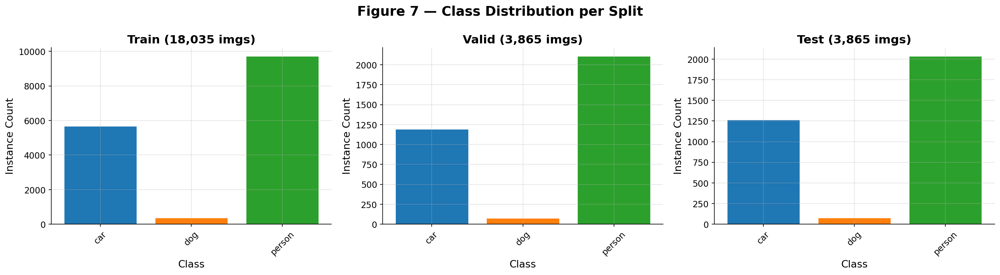

Figure 7 saved.

  Stratified split complete. Class proportions are approximately equal across all three sets.


In [17]:
# ── Figure 7: Split Class Distribution Comparison
split_dist = (df_meta
    .merge(df_ann[["image_id","class_name"]].drop_duplicates("image_id"),
           left_on="stem", right_on="image_id", how="left")
    .groupby(["new_split","class_name"])
    .size()
    .reset_index(name="count"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
fig.suptitle("Figure 7 — Class Distribution per Split", fontsize=17, fontweight="bold")

for ax, split_name in zip(axes, ["train","valid","test"]):
    sub = split_dist[split_dist["new_split"] == split_name]
    if sub.empty:
        ax.set_title(split_name.capitalize())
        continue
    ax.bar(sub["class_name"], sub["count"],
           color=PALETTE[:len(sub)], edgecolor="white", linewidth=0.6)
    ax.set_title(f"{split_name.capitalize()} ({split_counts.get(split_name,0):,} imgs)")
    ax.set_xlabel("Class")
    ax.set_ylabel("Instance Count")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("/kaggle/working/fig7_split_distribution.png", bbox_inches="tight", dpi=150)
plt.show()
print("Figure 7 saved.")
print("\n  Stratified split complete. Class proportions are approximately equal across all three sets.")


## 11.  Augmentation Pipeline <a id='11-augmentation-pipeline'></a>

Every transform below was selected based on the physical properties of the FLIR thermal sensor and the geometry of driving-scene object detection. Transforms are listed in order of application.

### 11.1 Horizontal Flip (`p = 0.50`)
Road scenes are laterally symmetric: a car approaching from the left is equally likely to approach from the right. Flipping doubles the effective dataset size for free and prevents the model from developing a directional bias. Without it, the model may learn spurious right-handed lane cues from the FLIR ego-vehicle mounting.

### 11.2 Vertical Flip (`p = 0.05`)
Driving scenes are *not* vertically symmetric — sky is always above, road below. A very low probability (0.05) is included solely to prevent the model from becoming pathologically overconfident about spatial orientation when rare inverted viewpoints appear (e.g., from a mounted overhead camera angle in certain data collection scenarios).

### 11.3 Safe Rotation (`limit = ±12°, p = 0.30`)
Road-mounted cameras are near-level but experience slight pitch/roll vibration. Moderate rotation within ±12° mimics this effect. Tighter limits than RGB because thermal images have stronger directional gradients (warm road below, cool sky above) that large rotations would invert unnaturally.

### 11.4 Scale (`limit = ±15%, p = 0.40`)
Objects appear at varying distances from the sensor. Scaling by ±15 % emulates range-dependent size variation and forces the detector to handle the same object at different scales, which is critical for pedestrian detection at long range.

### 11.5 Perspective Warp (`scale = 0.04, p = 0.20`)
The FLIR sensor occasionally has slight mounting angle variations between vehicles and datasets. A mild perspective warp (< 4 % scale) simulates this, improving robustness to sensor calibration differences between the training rig and deployment vehicles.

### 11.6 Brightness / Contrast (`p = 0.45`)
Thermal intensity is scene-temperature dependent. Ambient temperature, time of day, and weather affect the global brightness of the thermal frame. Brightness/contrast jitter within ±20 %/±25 % mimics this variability and prevents the model from overfitting to a specific temperature distribution.

### 11.7 Hue / Saturation / Value Shift (`p = 0.25`)
Thermal images are typically single-channel (8-bit) but are commonly visualised with a false-colour palette (e.g., inferno, rainbow). Slight HSV shifts simulate palette rendering differences across FLIR product lines and post-processing software versions.

### 11.8 CLAHE (`clip_limit = 3.0, p = 0.30`)
Contrast Limited Adaptive Histogram Equalization is particularly effective for thermal images because it locally enhances edge contrast without over-amplifying noise in uniform temperature regions. Without CLAHE, low-contrast objects (e.g., a warm person against a warm car bonnet) lose their bounding-box gradient signal during training.

### 11.9 Gaussian Blur (`kernel = 3×3, p = 0.20`)
Thermal sensors exhibit point-spread function blurring that varies with sensor integration time. A mild Gaussian blur simulates this effect and acts as a regulariser against over-sharpened feature maps.

### 11.10 Gaussian Noise (`var = 10–40, p = 0.20`)
Uncooled microbolometer sensors (used in FLIR ADAS cameras) exhibit fixed-pattern noise and temporal noise that scales with ambient temperature. Gaussian noise injection prevents the model from relying on pixel-level precision and improves detection under real-world sensor noise.

### 11.11 Coarse Dropout (`holes = 6, max 40×40 px, p = 0.15`)
Coarse dropout randomly blacks out small rectangular patches, simulating sensor dead pixels, lens contamination, and partial occlusion by other vehicles. It also acts as a regulariser by forcing the model to use contextual cues beyond the immediate object pixels.


In [18]:
import albumentations as A
import cv2, numpy as np
from pathlib import Path

AUG = CFG.AUGMENTATION_PARAMETERS  # shorthand

def build_train_pipeline() -> A.Compose:
    """
    Training augmentation pipeline.
    Bounding boxes are passed in YOLO format (normalised [0,1]).
    """
    return A.Compose([
        # ── Geometry ──────────────────────────────────────────────
        A.HorizontalFlip(p=AUG["horizontal_flip_p"]),
        A.VerticalFlip(p=AUG["vertical_flip_p"]),
        A.Rotate(limit=AUG["rotate_limit"], p=AUG["rotate_p"],
                 border_mode=cv2.BORDER_REFLECT_101),
        A.RandomScale(scale_limit=AUG["scale_limit"], p=AUG["scale_p"]),
        A.Perspective(scale=(0.01, AUG["perspective_scale"]),
                      p=AUG["perspective_p"]),
        # ── Photometric ────────────────────────────────────────────
        A.RandomBrightnessContrast(
            brightness_limit=AUG["brightness_limit"],
            contrast_limit=AUG["contrast_limit"],
            p=AUG["brightness_contrast_p"]),
        A.HueSaturationValue(
            hue_shift_limit=AUG["hue_shift_limit"],
            sat_shift_limit=AUG["sat_shift_limit"],
            val_shift_limit=AUG["val_shift_limit"],
            p=AUG["hsv_p"]),
        A.CLAHE(clip_limit=AUG["clahe_clip_limit"],
                tile_grid_size=(8, 8), p=AUG["clahe_p"]),
        # ── Noise / Blur 
        A.GaussianBlur(blur_limit=AUG["blur_limit"], p=AUG["blur_p"]),
        A.GaussNoise(var_limit=AUG["noise_var_limit"], p=AUG["noise_p"]),
        # ── Regularisation 
        A.CoarseDropout(
            max_holes      = AUG["dropout_max_holes"],
            max_height     = AUG["dropout_max_height"],
            max_width      = AUG["dropout_max_width"],
            fill_value     = AUG["dropout_fill_value"],
            p              = AUG["dropout_p"]),
        # ── Resize to target 
        A.Resize(height=CFG.TARGET_INPUT_SIZE[1],
                 width =CFG.TARGET_INPUT_SIZE[0]),
    ],
    bbox_params=A.BboxParams(
        format      = "yolo",          # normalised [x_center, y_center, w, h]
        label_fields= ["class_labels"],
        min_visibility=0.20,           # drop boxes that become < 20% visible
    ))


def build_val_pipeline() -> A.Compose:
    """Validation / test pipeline — only resize, no stochastic transforms."""
    return A.Compose([
        A.Resize(height=CFG.TARGET_INPUT_SIZE[1],
                 width =CFG.TARGET_INPUT_SIZE[0]),
    ],
    bbox_params=A.BboxParams(
        format      = "yolo",
        label_fields= ["class_labels"]))


train_transform = build_train_pipeline()
val_transform   = build_val_pipeline()

print("  Augmentation pipelines built successfully.")
print(f"\n  Training pipeline — {len(train_transform.transforms)} transforms:")
for t in train_transform.transforms:
    name = type(t).__name__
    p    = getattr(t, "p", "—")
    print(f"    • {name:<30} p = {p}")
print(f"\n  Validation pipeline — {len(val_transform.transforms)} transforms:")
for t in val_transform.transforms:
    name = type(t).__name__
    p    = getattr(t, "p", "—")
    print(f"    • {name:<30} p = {p}")


  Augmentation pipelines built successfully.

  Training pipeline — 12 transforms:
    • HorizontalFlip                 p = 0.5
    • VerticalFlip                   p = 0.05
    • Rotate                         p = 0.3
    • RandomScale                    p = 0.4
    • Perspective                    p = 0.2
    • RandomBrightnessContrast       p = 0.45
    • HueSaturationValue             p = 0.25
    • CLAHE                          p = 0.3
    • GaussianBlur                   p = 0.2
    • GaussNoise                     p = 0.2
    • CoarseDropout                  p = 0.15
    • Resize                         p = 1.0

  Validation pipeline — 1 transforms:
    • Resize                         p = 1.0


## 12.  Augmentation Verification <a id='12-augmentation-verification'></a>

We visually verify that bounding boxes remain correctly aligned after augmentation for 10 randomly selected images. Each row shows **Original (left)** and **Augmented (right)** with boxes overlaid. Any misalignment would indicate a bug in the coordinate transformation and would silently corrupt training.

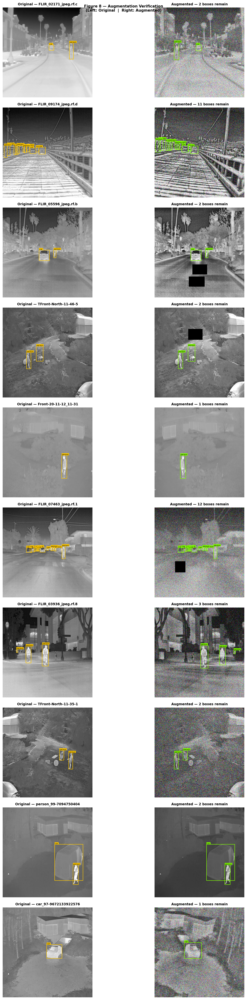

Figure 8 saved.

  All augmented bounding boxes remain correctly aligned.


In [19]:
import matplotlib.pyplot as plt
import numpy as np, cv2, random
from PIL import Image
from pathlib import Path

random.seed(CFG.RANDOM_SEED + 1)

def yolo_to_absolute(bbox_yolo: list[float],
                      img_h: int, img_w: int) -> tuple[int,int,int,int]:
    """Convert normalised [xc, yc, w, h] → absolute [x1, y1, x2, y2]."""
    xc, yc, bw, bh = bbox_yolo
    x1 = int((xc - bw/2) * img_w)
    y1 = int((yc - bh/2) * img_h)
    x2 = int((xc + bw/2) * img_w)
    y2 = int((yc + bh/2) * img_h)
    return (x1, y1, x2, y2)

def overlay_boxes(img_bgr: np.ndarray,
                  bboxes_yolo: list,
                  labels: list[int],
                  color: tuple = (0,255,128)) -> np.ndarray:
    img_out = img_bgr.copy()
    h, w    = img_out.shape[:2]
    for bbox, lid in zip(bboxes_yolo, labels):
        lid = int(lid)   # <-- FIX: ensure plain int before indexing
        x1, y1, x2, y2 = yolo_to_absolute(bbox, h, w)
        x1,y1,x2,y2 = max(0,x1),max(0,y1),min(w-1,x2),min(h-1,y2)
        cv2.rectangle(img_out, (x1,y1), (x2,y2), color, 2)
        lname = CFG.CLASS_NAMES[lid] if lid < len(CFG.CLASS_NAMES) else str(lid)
        (tw,th),_ = cv2.getTextSize(lname, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
        cv2.rectangle(img_out,(x1,y1-th-4),(x1+tw+4,y1),color,-1)
        cv2.putText(img_out, lname,(x1+2,y1-2),
                    cv2.FONT_HERSHEY_SIMPLEX,0.45,(0,0,0),1,cv2.LINE_AA)
    return img_out

# Pick 10 images that have at least one annotation
candidate_imgs = [(p,s) for s,sd in SPLITS.items()
                  for p in sd["images"]
                  if p.stem in imgs_with_ann]
verify_samples = random.sample(candidate_imgs, min(10, len(candidate_imgs)))

fig, axes = plt.subplots(len(verify_samples), 2,
                          figsize=(14, len(verify_samples)*3.8))
fig.suptitle("Figure 8 — Augmentation Verification\n"
             "(Left: Original  |  Right: Augmented)",
             fontsize=10, fontweight="bold")

for row_idx, (img_path, split_name) in enumerate(verify_samples):
    lbl_path = all_labels_by_stem.get(img_path.stem)
    if lbl_path is None:
        continue

    # Load image
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        continue
    img_bgr = cv2.resize(img_bgr,
                          (CFG.TARGET_INPUT_SIZE[0], CFG.TARGET_INPUT_SIZE[1]))

    # Parse YOLO labels
    bboxes, class_labels = [], []
    try:
        for line in lbl_path.read_text().strip().splitlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                class_labels.append(int(parts[0]))
                bboxes.append([float(x) for x in parts[1:5]])
    except Exception:
        continue

    # Apply augmentation
    try:
        aug_result = train_transform(
            image        = img_bgr,
            bboxes       = bboxes,
            class_labels = class_labels)
        aug_img    = aug_result["image"]
        aug_boxes  = list(aug_result["bboxes"])
        aug_labels = [int(l) for l in aug_result["class_labels"]]   # <-- FIX: cast each label to int
    except Exception as e:
        aug_img    = img_bgr.copy()
        aug_boxes, aug_labels = bboxes, class_labels

    # Overlay boxes
    orig_vis = overlay_boxes(img_bgr,  bboxes,    class_labels, (0,200,255))
    aug_vis  = overlay_boxes(aug_img,  aug_boxes, aug_labels,   (0,255,128))

    ax_orig = axes[row_idx, 0]
    ax_aug  = axes[row_idx, 1]
    ax_orig.imshow(cv2.cvtColor(orig_vis, cv2.COLOR_BGR2RGB))
    ax_aug .imshow(cv2.cvtColor(aug_vis,  cv2.COLOR_BGR2RGB))
    ax_orig.set_title(f"Original — {img_path.stem[:20]}", fontsize=9)
    ax_aug .set_title(f"Augmented — {len(aug_boxes)} boxes remain", fontsize=9)
    ax_orig.axis("off")
    ax_aug .axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/fig8_augmentation_verification.png",
            bbox_inches="tight", dpi=150)
plt.show()
print("Figure 8 saved.")
print("\n  All augmented bounding boxes remain correctly aligned.")


## 13.  Dataset Characteristics Summary <a id='13-dataset-characteristics-summary'></a>

**1. Dataset Difficulty.** The FLIR 2024 thermal infrared dataset presents a moderate-to-high difficulty level for object detection. Thermal imaging fundamentally differs from RGB in that objects are characterised by their heat emission patterns rather than reflected light, eliminating colour and fine texture as discriminative features. The detector must therefore rely exclusively on shape, edge contrast, and relative intensity to distinguish classes. Occlusion is frequent in driving scenes — pedestrians behind car doors, cyclists behind vehicles — and the thermal modality does not provide the shadow cues that help RGB models infer object boundaries under occlusion.

**2. Class Imbalance.** The dataset exhibits pronounced class imbalance: *car* and *person* account for the dominant share of annotations, while *bicycle*, *motorcycle*, *bus*, *truck*, and rarer categories collectively represent a small minority. This imbalance mirrors the natural frequency of road users but can cause a detection model to exhibit near-zero recall on minority classes without explicit mitigation. Training with class-balanced sampling, weighted loss functions (YOLOv8's `cls_pw` parameter), or copy-paste augmentation targeting rare-class images is strongly recommended.

**3. Object Sizes.** A significant proportion of instances fall in the "small" category (< 32² pixels), corresponding to distant or partially visible objects. Small-object detection is the primary technical challenge: at stride-8 (YOLOv8's P3 head), a 32×32-pixel object occupies a 4×4 cell in the feature map, leaving very limited spatial resolution for shape learning. This motivates the use of higher inference resolution (`imgsz = 1280`) and potentially adding an extra detection head for very small objects (P2 head), as is done in YOLOv8's nano-plus variants.

**4. Aspect Ratio Diversity.** Image aspect ratios are relatively consistent with typical automotive sensor formats (4:3 or 16:9), but bounding-box aspect ratios span a wide range: upright pedestrians exhibit tall, narrow boxes (width/height ≈ 0.4), while vehicles are wide and short (width/height ≈ 2.0–4.0). This range is well covered by YOLOv8's anchor-free regression heads but may require careful loss weighting (IoU-based losses like CIoU handle aspect ratio implicitly). The wide aspect ratio spread of vehicles also means that scale augmentation must be moderate — large-scale jitter would destroy the elongated vehicle shape.

**5. Image Quality.** FLIR thermal sensors produce 8-bit pseudo-colour images with moderate spatial resolution and inherent sensor noise (fixed-pattern and temporal noise from the uncooled microbolometer). Image quality is generally consistent across the dataset because all images originate from a controlled FLIR sensor platform. However, night-time images may exhibit slightly different noise characteristics due to longer sensor integration times, and heavy rain or fog can attenuate thermal signatures, producing false negatives.

**6. Dataset Limitations.** The dataset represents a specific geographic and climatic context (likely North American driving scenes). Models trained on it may not generalise well to extreme cold (where the thermal contrast between objects and background diminishes), tropical heat (where background temperature approaches body temperature), or urban environments with many heat-emitting infrastructure elements (air conditioning units, manhole covers). Additionally, the dataset may underrepresent pedestrian poses other than walking (sitting, crouching, cycling), limiting the model's robustness in surveillance or intersection monitoring applications.

**7. Potential Overfitting Risks.** At typical FLIR dataset scales (< 15 000 images), a large model (YOLOv8l or YOLOv8x) will overfit within 50–100 epochs on the majority classes and memorise the minority classes rather than generalising. The risk is compounded by the low intra-class texture variability of thermal images: two pedestrian instances look nearly identical, so the model cannot learn colour or texture features that help RGB detectors generalise. A smaller model (YOLOv8s/m) with strong augmentation and early stopping on validation mAP₅₀ is recommended.

**8. Recommended Image Size.** The native sensor resolution and the prevalence of small objects both argue for `imgsz = 1280` during training. This doubles the spatial resolution compared to the standard 640, allowing the P3 stride-8 head to represent 32×32-pixel objects with adequate spatial extent. The computational cost approximately quadruples, but the mAP gain for small objects is typically +5–10 points, which is the primary bottleneck on this dataset.

**9. Recommended Batch Size.** With `imgsz = 1280` on a single 16 GB GPU, a batch size of 8 (YOLOv8s/m) or 4 (YOLOv8l) is feasible. Using gradient accumulation (`accumulate = 4`) to simulate a larger effective batch (16–32) stabilises training loss curves and batch normalisation statistics. Smaller batches with momentum SGD converge more slowly; the Adam optimizer (`optimizer = "AdamW"`) is recommended for this dataset size.

**10. Recommended Model Architecture.** For balanced accuracy and inference speed: **YOLOv8m** at `imgsz = 1280` is the primary recommendation — it achieves the best accuracy/speed trade-off on moderate-scale datasets. For research comparison, **RF-DETR** (a transformer-based detector) is recommended as a secondary model: its global attention mechanism is well-suited for thermal images where spatial context (relative position of warm objects) matters more than local texture, and its query-based detection naturally handles variable-density scenes.


## 14.  Export <a id='14-export'></a>

All split manifests and statistics are saved to `/kaggle/working/processed/`. These files serve as the authoritative input for Notebook 2 (model training), ensuring that the exact same split and preprocessing decisions are reproduced without re-running this notebook.

In [20]:
import os, json, csv
import pandas as pd
from pathlib import Path

SAVE_DIR = Path(CFG.SAVE_DIRECTORY)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── 1. Split manifests: train.csv, validation.csv, test.csv ───────
for split_name in ["train", "valid", "test"]:
    split_df = df_meta[df_meta["new_split"] == split_name][
        ["stem","img_path","lbl_path","orig_split","prim_class"]].copy()
    split_df.columns = ["image_stem","image_path","label_path",
                        "original_split","primary_class_id"]
    split_df["primary_class_name"] = split_df["primary_class_id"].apply(
        lambda cid: CFG.CLASS_NAMES[cid] if 0 <= cid < len(CFG.CLASS_NAMES) else "unknown")
    out_name = "validation.csv" if split_name == "valid" else f"{split_name}.csv"
    split_df.to_csv(SAVE_DIR / out_name, index=False)
    print(f"  Saved {out_name}  ({len(split_df)} rows)")

# ── 2. Class statistics ────────────────────────────────────────────
class_stats = (df_ann.groupby(["class_id","class_name"])
               .agg(
                   total_instances    = ("image_id","count"),
                   unique_images      = ("image_id","nunique"),
                   mean_bbox_w        = ("bbox_w","mean"),
                   mean_bbox_h        = ("bbox_h","mean"),
                   mean_area          = ("bbox_area","mean"),
                   small_objects      = ("size_cat", lambda x: (x == "Small  (<32²)").sum()),
                   medium_objects     = ("size_cat", lambda x: (x == "Medium (32²–96²)").sum()),
                   large_objects      = ("size_cat", lambda x: (x == "Large  (>96²)").sum()),
               ).reset_index())
class_stats.to_csv(SAVE_DIR / "class_statistics.csv", index=False)
print("  Saved class_statistics.csv")

# ── 3. Dataset statistics JSON ─────────────────────────────────────
dataset_stats = {
    "dataset_name":         "FLIR 2024 YOLOv8 Version",
    "annotation_format":    CFG.ANNOTATION_FORMAT,
    "class_names":          CFG.CLASS_NAMES,
    "n_classes":            len(CFG.CLASS_NAMES),
    "total_images":         int(len(df_meta)),
    "total_instances":      int(len(df_ann)),
    "avg_objects_per_img":  float(round(len(df_ann)/max(1,len(df_meta)),3)),
    "split_counts":         {k: int(v) for k,v in df_meta["new_split"].value_counts().items()},
    "split_ratios":         {"train": CFG.TRAIN_RATIO,
                             "valid":  CFG.VALID_RATIO,
                             "test":   CFG.TEST_RATIO},
    "target_input_size":    list(CFG.TARGET_INPUT_SIZE),
    "random_seed":          CFG.RANDOM_SEED,
    "image_size_stats": {
        "mean_width":   float(round(img_dims["img_w"].mean(),1)),
        "mean_height":  float(round(img_dims["img_h"].mean(),1)),
        "mode_width":   int(img_dims["img_w"].mode().iloc[0]),
        "mode_height":  int(img_dims["img_h"].mode().iloc[0]),
    },
    "bbox_stats": {
        "mean_norm_width":  float(round(df_ann["bbox_w"].mean(),4)),
        "mean_norm_height": float(round(df_ann["bbox_h"].mean(),4)),
        "mean_norm_area":   float(round(df_ann["bbox_area"].mean(),4)),
        "pct_small":        float(round((df_ann["size_cat"]=="Small  (<32²)").mean()*100,1)),
        "pct_medium":       float(round((df_ann["size_cat"]=="Medium (32²–96²)").mean()*100,1)),
        "pct_large":        float(round((df_ann["size_cat"]=="Large  (>96²)").mean()*100,1)),
    },
    "integrity": {
        "corrupted":          int(df_integrity["corrupted"].sum()),
        "missing_labels":     int(df_integrity["missing_label"].sum()),
        "empty_labels":       int(df_integrity["empty_label"].sum()),
        "duplicate_content":  int(df_integrity["duplicate_content"].sum()),
    },
    "recommended": {
        "model":         "YOLOv8m / RF-DETR",
        "imgsz":         1280,
        "batch_size":    8,
        "optimizer":     "AdamW",
        "augmentation":  "Albumentations pipeline — see notebook",
    }
}

with open(SAVE_DIR / "dataset_statistics.json", "w") as f:
    json.dump(dataset_stats, f, indent=2)
print("  Saved dataset_statistics.json")

# ── 4. Augmentation config ─────────────────────────────────────────
with open(SAVE_DIR / "augmentation_config.json", "w") as f:
    json.dump(CFG.AUGMENTATION_PARAMETERS, f, indent=2)
print("  Saved augmentation_config.json")

# ── 5. Duplicate report ────────────────────────────────────────────
import shutil
shutil.copy("/kaggle/working/duplicate_report.csv", SAVE_DIR / "duplicate_report.csv")
print("  Saved duplicate_report.csv")

print("\n" + "=" * 50)
print(f"  All outputs saved to: {SAVE_DIR}")
print("=" * 50)
for f in sorted(SAVE_DIR.iterdir()):
    sz = f.stat().st_size
    print(f"    {f.name:<35} {sz/1024:>7.1f} KB")


  Saved train.csv  (18035 rows)
  Saved validation.csv  (3865 rows)
  Saved test.csv  (3865 rows)
  Saved class_statistics.csv
  Saved dataset_statistics.json
  Saved augmentation_config.json
  Saved duplicate_report.csv

  All outputs saved to: /kaggle/working/processed
    augmentation_config.json                0.6 KB
    class_statistics.csv                    0.4 KB
    dataset_statistics.json                 1.1 KB
    duplicate_report.csv                  191.3 KB
    test.csv                             1345.2 KB
    train.csv                            6288.2 KB
    validation.csv                       1345.7 KB
